# Structures and variants: sizes, a forward pass, schematics

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
import torch
from backbone.config import load_run_config, list_variants
from backbone.model import EncoderModel, count_parameters
from backbone.data import Dataset, load_vocab
V = len(load_vocab()); ds = Dataset("mix", "valid")
tok, tgt, pad = ds.batch(torch.arange(32))
rows = []
for s in ["dense", "dense_wide", "moe", "moh", "moa", "momha", "mom", "mita"]:
    for v in list_variants(s):
        cfg = load_run_config(s, v, {"vocab_size": V}); torch.manual_seed(0)
        m = EncoderModel(cfg, V); m.state.record = True
        with torch.no_grad(): logits, aux = m(tok, pad)
        rows.append({"structure": s, "variant": v, "params (no emb/head)": count_parameters(m),
                     "routed modules": len(m.routed_modules())})
display(pd.DataFrame(rows))

,structure,variant,params (no emb/head),routed modules
0,dense,default,395776,0
1,dense_wide,default,1185280,0
2,moe,default,1222144,2
3,moe,hash,1187072,2
4,moe,top1,1189120,2
5,moh,default,529152,2
6,moh,k6,529152,2
7,moh,shared2,529664,2
8,moa,default,414208,2
9,moa,k8,414208,2


## Schematics (drawn by analysis/schematics.py)

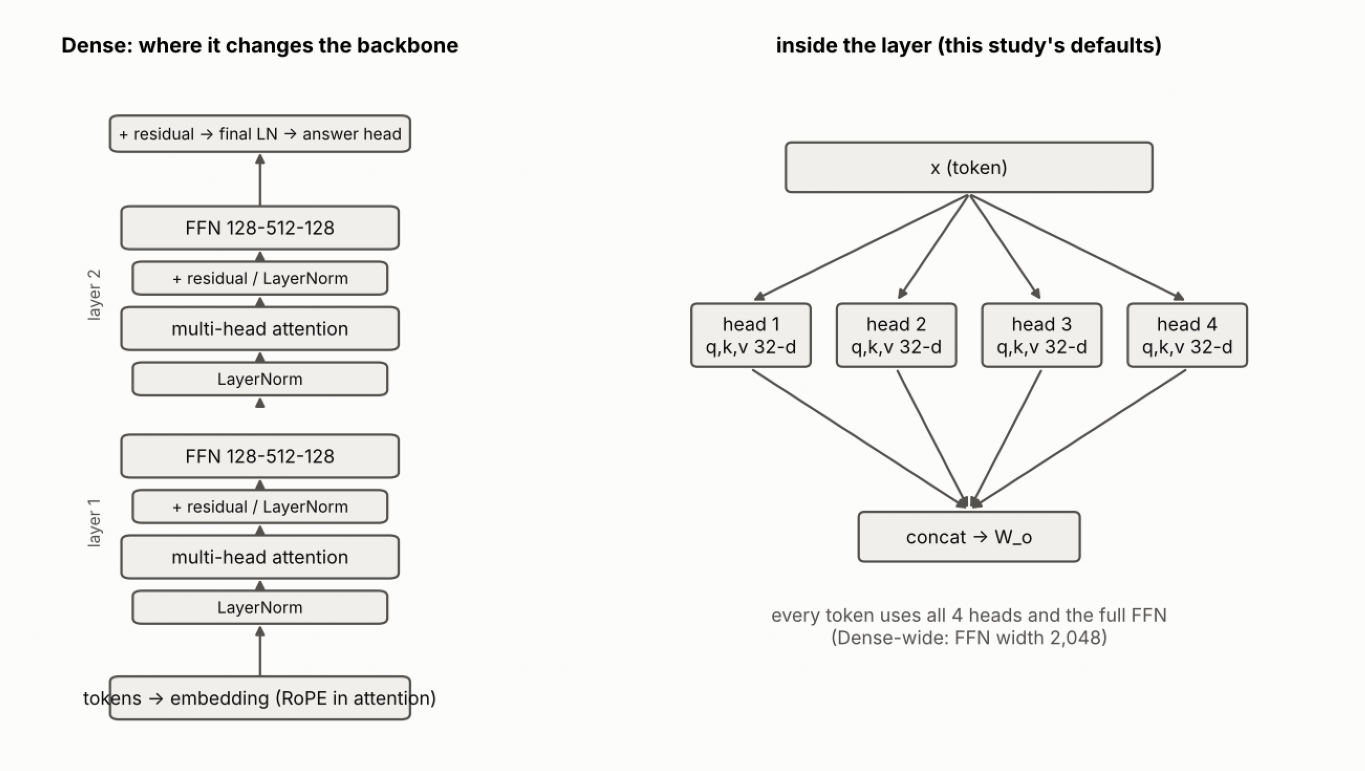

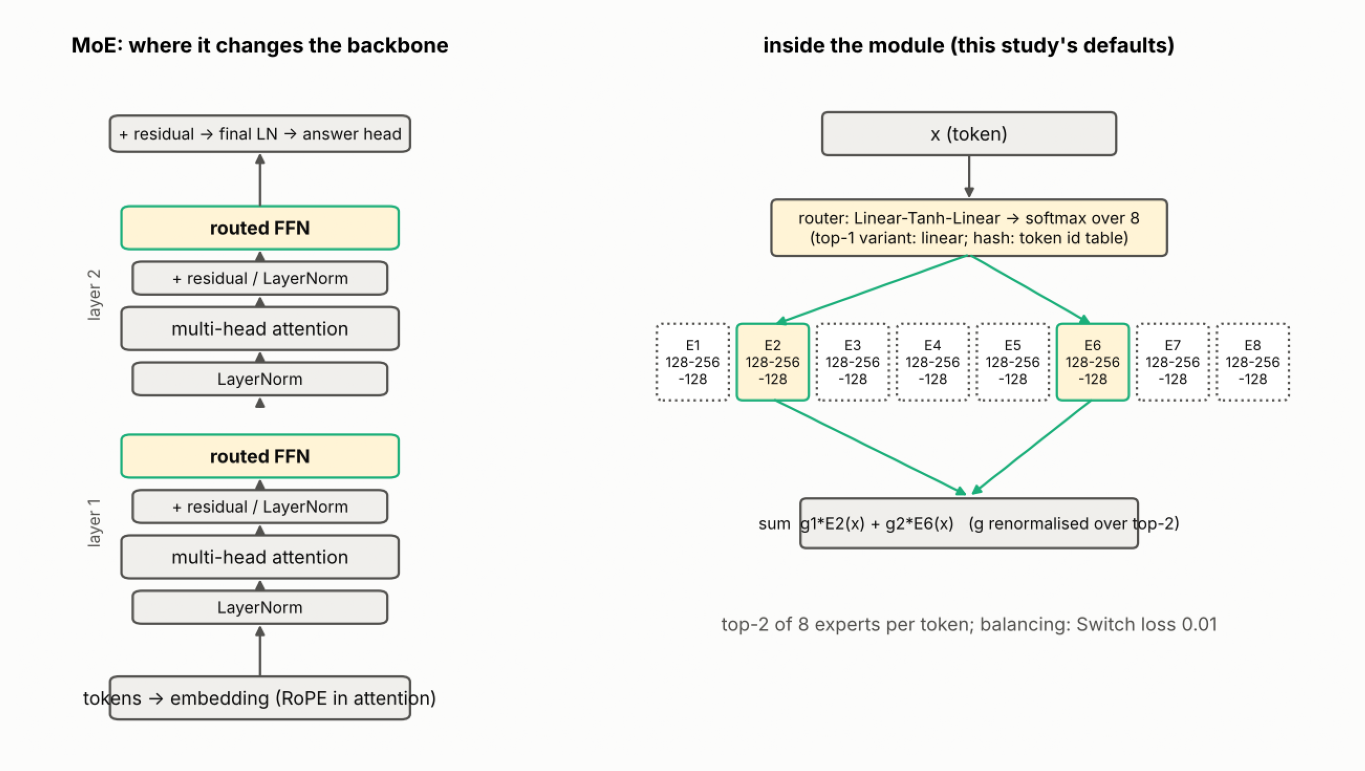

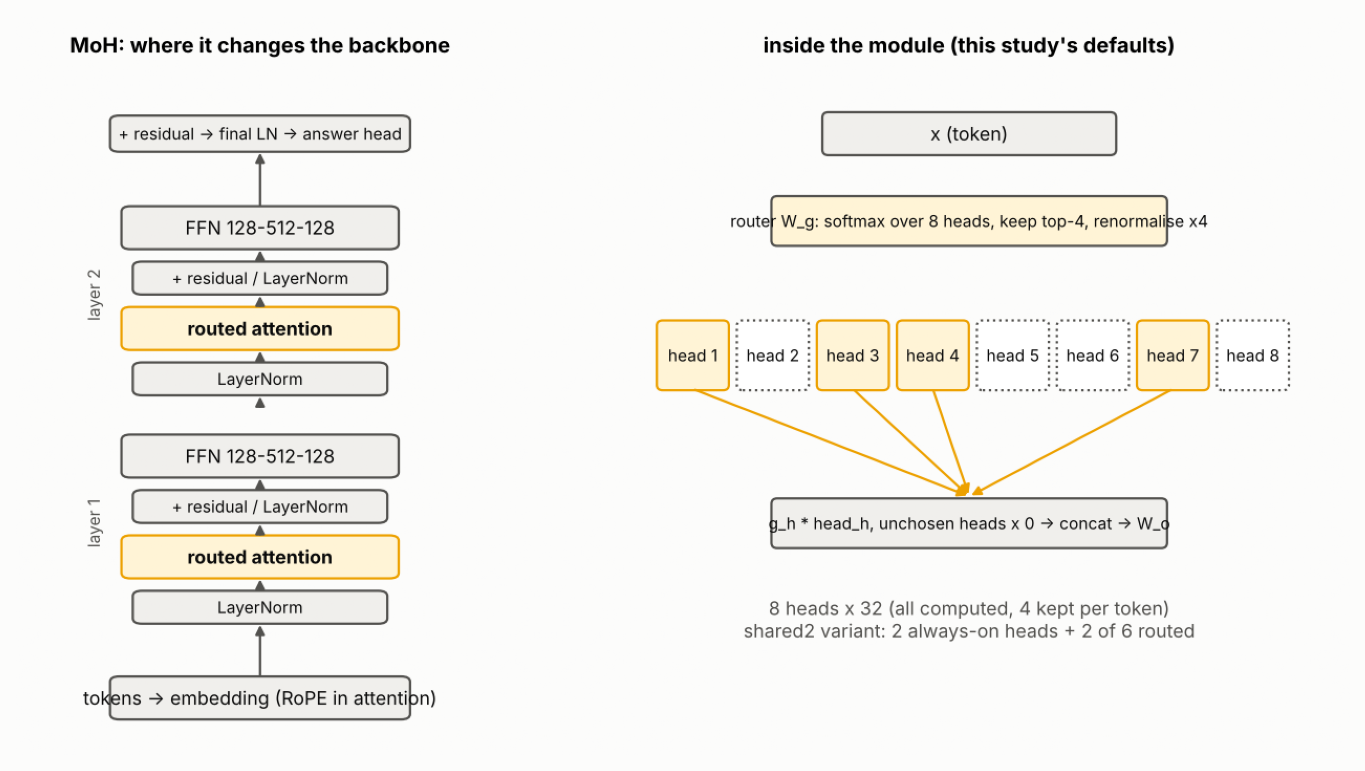

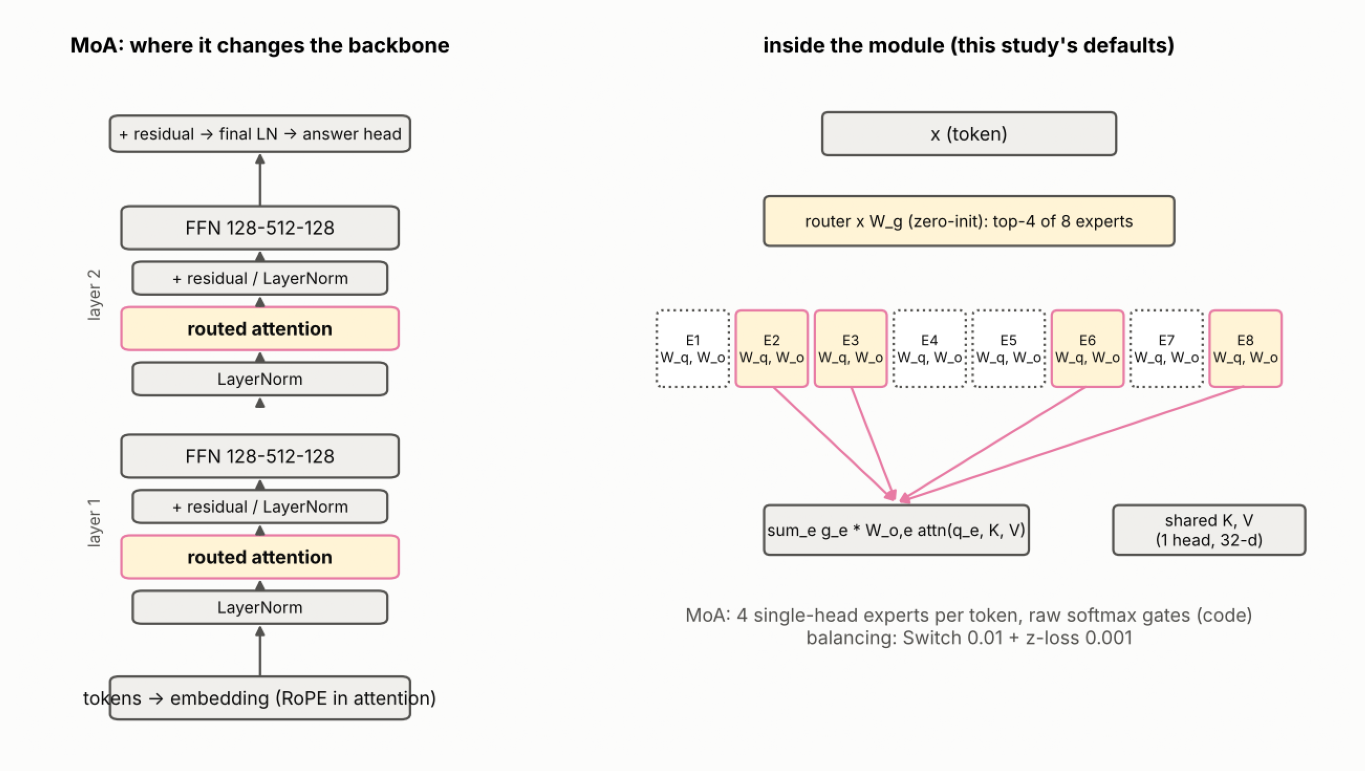

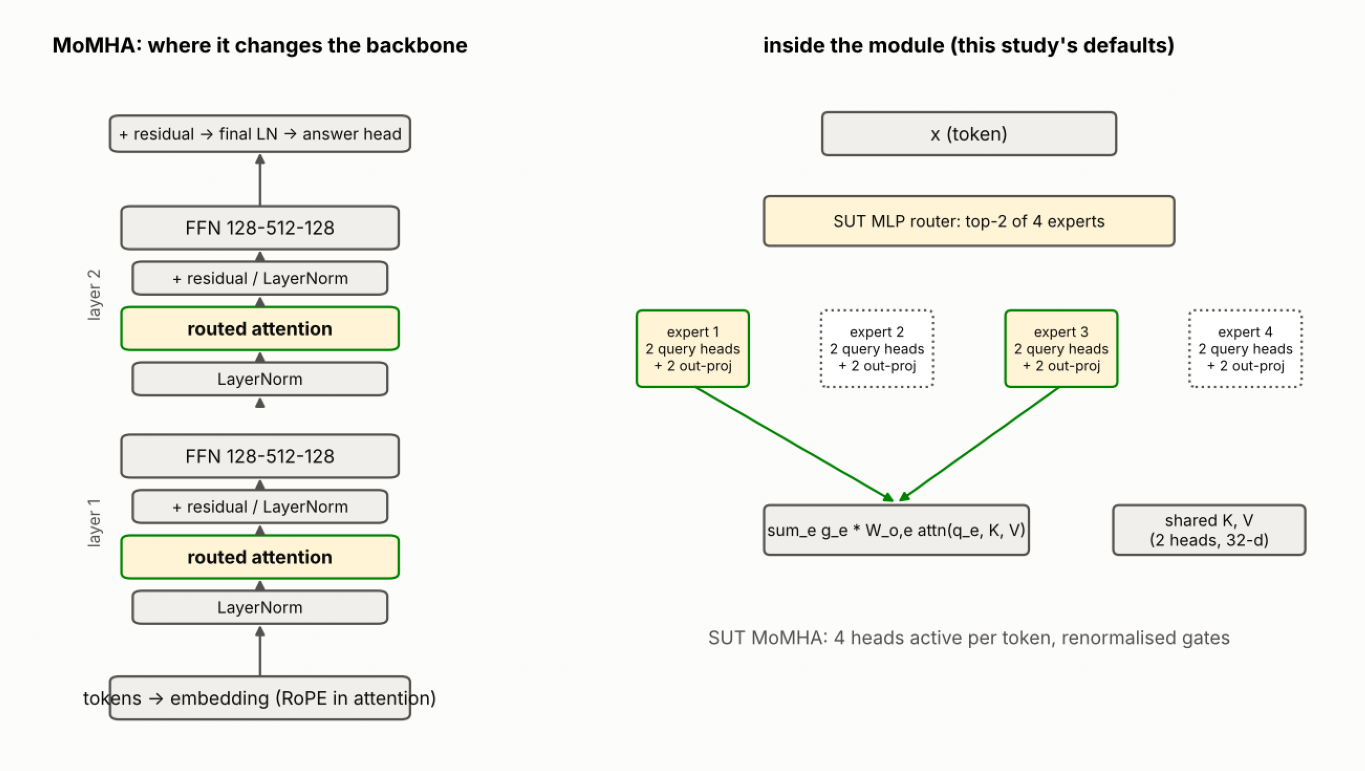

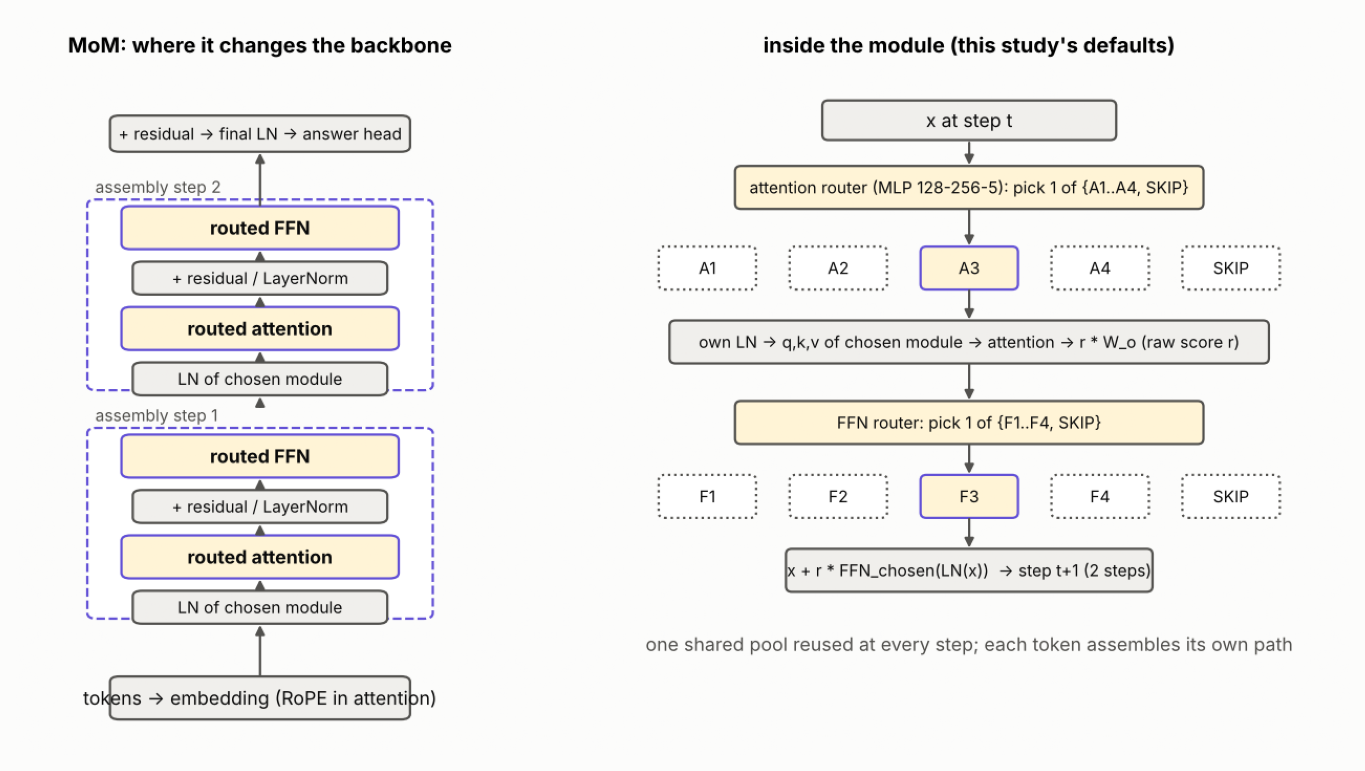

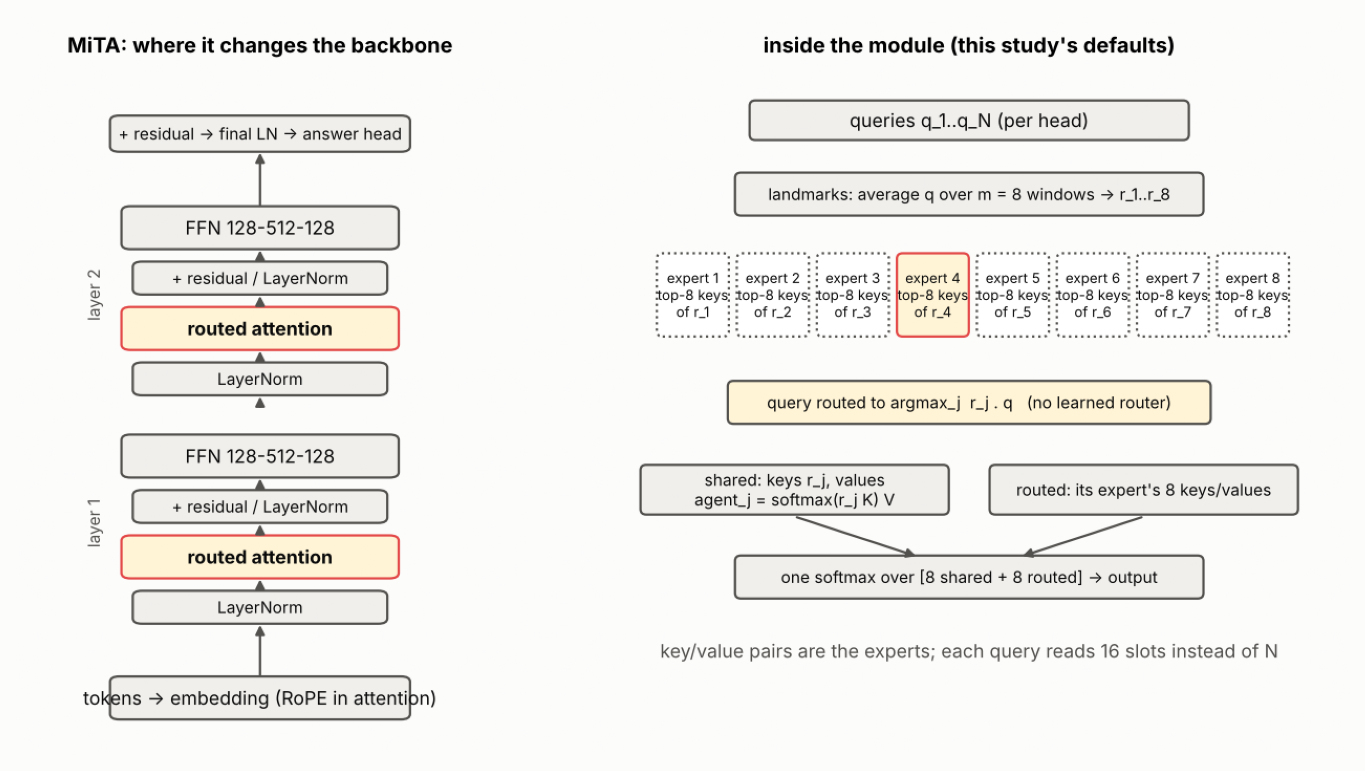

In [3]:
from analysis.schematics import draw
import matplotlib.pyplot as plt, matplotlib.image as mpimg
for s in ["dense", "moe", "moh", "moa", "momha", "mom", "mita"]:
    p = draw(s); plt.figure(figsize=(12, 6)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()